# Exercise 6: file formats

The volunteers of five hobby stations write down their rain gauge every morning, in `../../data/raw/rain_logbook.xlsx`: one sheet per station.

In [1]:
import pandas as pd

**6.1** Read the HS01 sheet, with the right column names. The volunteers write "?" when a reading is
unknown: make sure `Rain` is a number column. How much rain fell at HS01 in 2023?

Docs: [`pd.read_excel`](https://pandas.pydata.org/docs/reference/api/pandas.read_excel.html)

In [2]:
hs01 = pd.read_excel(
    "../../data/raw/rain_logbook.xlsx", sheet_name="HS01", skiprows=[0, 1, 3], na_values=["?"]
)
hs01

,Date,Rain,Remarks
0,2023-01-01,0.0,NaN
1,2023-01-02,4.2,NaN
2,2023-01-03,0.5,NaN
3,2023-01-04,3.1,NaN
4,2023-01-05,1.9,NaN
...,...,...,...
360,2023-12-27,1.0,NaN
361,2023-12-28,0.0,NaN
362,2023-12-29,0.2,NaN
363,2023-12-30,5.6,NaN


In [3]:
hs01["Rain"].sum()

np.float64(1009.0)

About 1 009 mm.

**6.2** Read the sheets of all five stations, each with a column `station`, and put them in one DataFrame.
How much rain did each station record? Plot the totals as a bar chart (`kind="bar"`).

In [4]:
sheets = []
for station in ["HS01", "HS02", "HS03", "HS04", "HS05"]:
    sheet = pd.read_excel(
        "../../data/raw/rain_logbook.xlsx", sheet_name=station, skiprows=[0, 1, 3], na_values=["?"]
    ).assign(station=station)
    sheets.append(sheet)
logbook = pd.concat(sheets, ignore_index=True)
logbook

,Date,Rain,Remarks,station
0,2023-01-01,0.0,NaN,HS01
1,2023-01-02,4.2,NaN,HS01
2,2023-01-03,0.5,NaN,HS01
3,2023-01-04,3.1,NaN,HS01
4,2023-01-05,1.9,NaN,HS01
...,...,...,...,...
1800,2023-12-07,0.5,NaN,HS05
1801,2023-12-28,0.5,NaN,HS05
1802,2023-12-29,0.8,NaN,HS05
1803,2023-12-30,0.7,NaN,HS05


Shorter, with a list comprehension. It makes the same DataFrame:

In [5]:
logbook = pd.concat(
    [
        pd.read_excel(
            "../../data/raw/rain_logbook.xlsx", sheet_name=station, skiprows=[0, 1, 3], na_values=["?"]
        ).assign(station=station)
        for station in ["HS01", "HS02", "HS03", "HS04", "HS05"]
    ],
    ignore_index=True,
)

In [6]:
totals = logbook.groupby("station")["Rain"].sum()
totals

station
HS01    1009.0
HS02     964.9
HS03     553.9
HS04     937.8
HS05     915.5
Name: Rain, dtype: float64

<Axes: xlabel='station'>

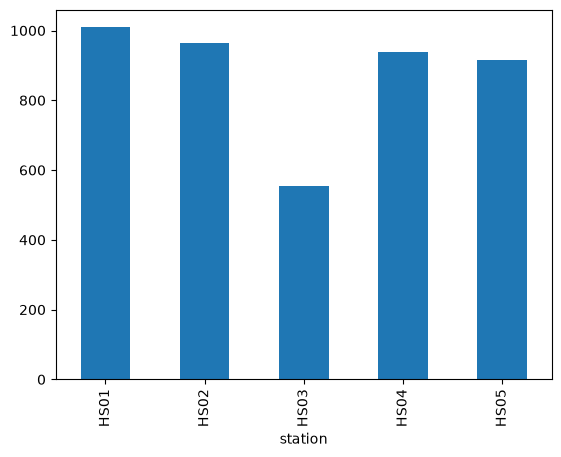

In [7]:
totals.plot(kind="bar")

**6.3** Save the combined logbook as Parquet, and read it back. Are the types still right?

In [8]:
logbook.to_parquet("../../data/rain_logbook.parquet")
pd.read_parquet("../../data/rain_logbook.parquet").dtypes

Date       datetime64[us]
Rain              float64
Remarks               str
station               str
dtype: object

The types are kept: `Date` is still a date, and `Rain` still a number.

## Bonus

Read all five sheets with a single `pd.read_excel` call, without a loop. Look up what `sheet_name` accepts.

Docs: [`pd.read_excel`](https://pandas.pydata.org/docs/reference/api/pandas.read_excel.html)

In [9]:
sheets = pd.read_excel(
    "../../data/raw/rain_logbook.xlsx",
    sheet_name=["HS01", "HS02", "HS03", "HS04", "HS05"],
    skiprows=[0, 1, 3],
    na_values=["?"],
)
pd.concat(sheets, names=["station", "row"]).reset_index().drop(columns="row")

,station,Date,Rain,Remarks
0,HS01,2023-01-01,0.0,NaN
1,HS01,2023-01-02,4.2,NaN
2,HS01,2023-01-03,0.5,NaN
3,HS01,2023-01-04,3.1,NaN
4,HS01,2023-01-05,1.9,NaN
...,...,...,...,...
1800,HS05,2023-12-07,0.5,NaN
1801,HS05,2023-12-28,0.5,NaN
1802,HS05,2023-12-29,0.8,NaN
1803,HS05,2023-12-30,0.7,NaN


With a list of sheet names, `read_excel` returns a dictionary: the sheet name, and its DataFrame.
`pd.concat` turns the keys of a dictionary into an extra level of the index, here called `station`.
`reset_index` turns both levels into columns, and we drop the old row numbers.